<a href="https://colab.research.google.com/github/etimush/MemoryNCA/blob/main/GeneCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EngramNCA**

In [112]:
#@title Get Packages and Images  { vertical-output: true}
%pip install git+https://github.com/etimush/MemoryNCA
#git clone --depth 1 --filter=blob:none --sparse https://github.com/etimush/MemoryNCA.git
%cd MemoryNCA && git sparse-checkout set Images
%mkdir Images && mv MemoryNCA/Images/* Images && rm -rf MemoryNCA

  Cloning https://github.com/etimush/MemoryNCA to c:\users\kurwinox\appdata\local\temp\pip-req-build-lu3dp0x8
  Resolved https://github.com/etimush/MemoryNCA to commit 67ce16ed9323382b8e18a659dbf30140994a0333
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.
[WinError 2] The system cannot find the file specified: 'MemoryNCA && git sparse-checkout set Images'
c:\Users\kurwinox\Documents\GitHub\EngramNCA


  Running command git clone --filter=blob:none --quiet https://github.com/etimush/MemoryNCA 'C:\Users\kurwinox\AppData\Local\Temp\pip-req-build-lu3dp0x8'
  on a case-insensitive filesystem) and only one from the same
  colliding group is in the working tree:

    'docs/figures/Gene.drawio.svg'
    'docs/figures/gene.drawio.svg'

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
A subdirectory or file Images already exists.


In [113]:
import torch
print("CUDA Available:", torch.cuda.is_available())

CUDA Available: True


In [114]:
#@title Imports { vertical-output: true}
import random
import numpy as np
import matplotlib.pyplot as plt
from NCA.NCA import *
import NCA.utils as utils
from IPython.display import Image, HTML, clear_output
import logging
import os
from IPython.display import display, HTML, Video
from PIL import Image
import cv2
from base64 import b64encode
logger = logging.getLogger()
old_level = logger.level
logger.setLevel(100)

In [115]:
#@title Setup { vertical-output: true}
PATH = "TRAINED_2"
DEVICE = "cuda:0" #<-- Device to use, CUDA recommended
HEIGHT = 30 #@param {type:"integer"}
WIDTH = 30 #@param {type:"integer"}
CHANNELS = 16 # @param {type:"integer"}<--- NCA feature channels
BATCH_SIZE = 21 #@param {type:"integer"}
PADDING = 5 #@param {type:"integer"}
GENE_COUNT = 8 #@param {type:"integer"} <-- Number of gene channels to use for "private" information
POOL_SIZE = 2666 #@param {type:"integer"}<--- NCA training pool size, lower values train faster but are less stable
TRAINING_ITERS = 8000  #@param {type:"integer"}<-- Number of trainign iterations
HIDDEN_SIZE = 64 #@param {type:"integer"}<--- NCA hidden size
PRIMITIVES_SHAPES = ["Images/square.png", "Images/circle.png", "Images/triangle.png"]
PRIMITIVES_BODY_PARTS = ["Images/Torso.png", "Images/Head.png", "Images/Tail.png", "Images/leg1.png", "Images/leg2.png", "Images/leg3.png", "Images/leg4.png"]
PRIMITIVES_LINES = ["Images/horizontal.png", "Images/Verical.png"]
style = """
<style>
.output_wrapper, .output {
    display: flex;
    flex-direction: row-reverse; /* Align content to the right */
}
</style>
"""


In [116]:
#@title Load Primitives { vertical-output: true}

paths = PRIMITIVES_BODY_PARTS #@param {type:"string"}
images = []
images_to_display = []
for path in paths:
    image, image_to_display = utils.get_image(path, HEIGHT, WIDTH, padding=PADDING)
    images.append(image)
    images_to_display.append(image_to_display)

genes = [[0], [6], [5], [4], [3], [2], [1]] # <-- Gene one hot encoding, indicates which bits if the gene sequence for each encoded "image" should be 1, [0] = 001, [0,1] = 011, [2] = 100 etc. for 3 bits genes. One, one-hot encoding per image, this rule applies for any gene size

HEIGHT = HEIGHT + 2*PADDING
WIDTH = WIDTH + 2*PADDING
assert len(paths) == len(genes), 'Genes and images should have the same length '

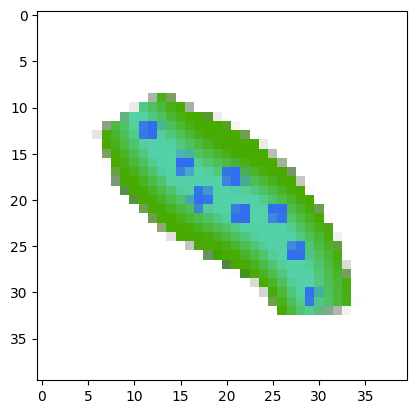

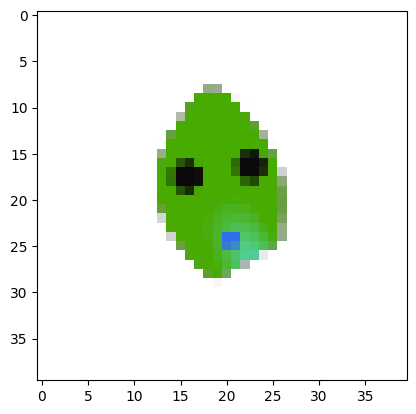

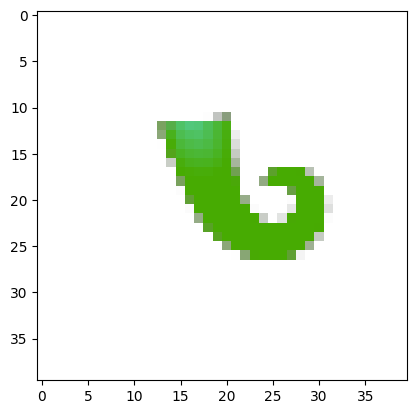

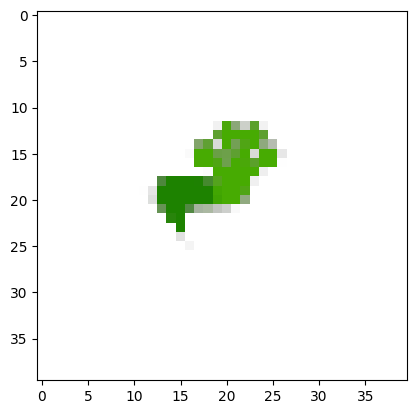

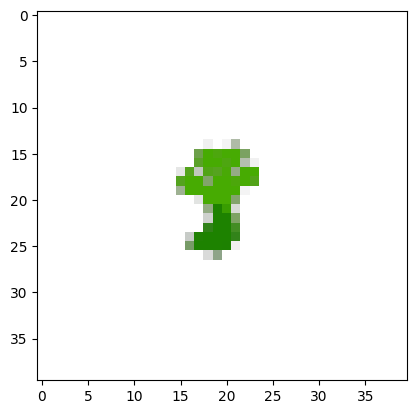

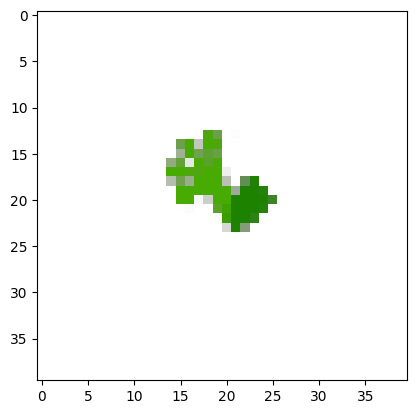

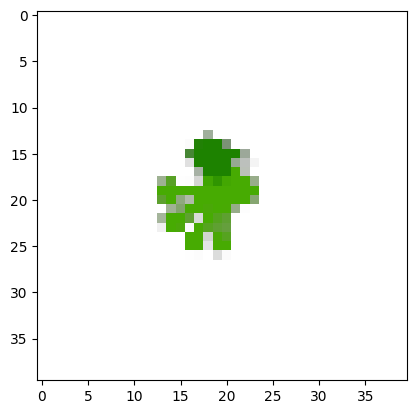

In [117]:
#@title Display Primitives { vertical-output: true}
for i,image in enumerate(images_to_display):
    plt.figure(3+i)
    plt.imshow(image)
pools = []
for gene in genes:
    pools.append(utils.make_gene_pool(gene, pool_size=POOL_SIZE,height=HEIGHT, width=WIDTH, channels=CHANNELS, gene_size=8))
seeds = []
for pool in pools:
    seeds.append(pool[0].clone())

In [118]:
#@title Get Batch Image Partitions { vertical-output: true}
partitions = len(paths)
if partitions == 1:
    part = [BATCH_SIZE]
div = BATCH_SIZE//partitions
rem = BATCH_SIZE % partitions
part = [div + 1 if i < rem else div for i in range(partitions)]
print(f"Batch image paritions = {part}. Batch Size of {BATCH_SIZE}. Number of Partitions = {partitions}")

Batch image paritions = [3, 3, 3, 3, 3, 3, 3]. Batch Size of 21. Number of Partitions = 7


In [119]:
#@title Load Filters for Loss Function { vertical-output: true}
sobel_x = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]], dtype=torch.float32, device="cuda:0")
lap = torch.tensor([[1.0, 2.0, 1.0], [2.0, -12, 2.0], [1.0, 2.0, 1.0]], dtype=torch.float32, device="cuda:0")
filters = torch.stack([sobel_x, sobel_x.T, lap])
folder = "Gene"

In [120]:
#@title Create Path for Saving Models { vertical-output: true}
path = f"{PATH}/" + folder
if not os.path.exists(path):
    os.makedirs(path)
    print(f"Path: {path} created")
else:
    print(f"Path: {path} already exists, all OK!")


Path: TRAINED_2/Gene already exists, all OK!


In [121]:
#@title Initialise NCA { vertical-output: true}
bases = [images[i].tile(part[i],1,1,1) for i in range(len(part))]
base = torch.cat(bases, dim =0 )
loss_log = []
nca = GeneCA(CHANNELS,HIDDEN_SIZE, gene_size=GENE_COUNT)
nca = nca.to(DEVICE)
optim = torch.optim.AdamW(nca.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=2000, gamma=0.3)
name = folder + "/" +type(nca).__name__ + "_gene_size_" +str(GENE_COUNT)

Batch


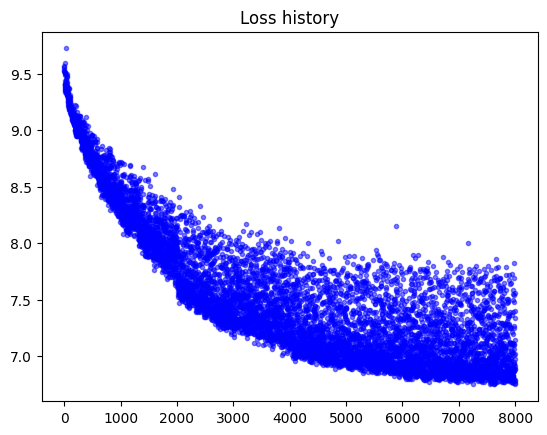

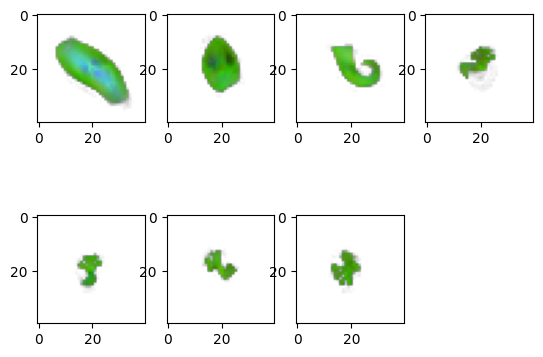

TRAINED_2/Gene/GeneCA_gene_size_8.pth


In [67]:
#@title Training { vertical-output: true}
for i in range(TRAINING_ITERS + 1):
    loss = 0
    with torch.no_grad():
        idxs, x = utils.get_gene_pool(pools, part, seeds)

    for _ in range( random.randrange(32,92)):
        x = nca(x)
    loss = (base - x[:, :4, :, :]).pow(2).sum() + 0.1 *(perchannel_conv(base, filters) - perchannel_conv(x[:, :4, :, :], filters) ).pow(2).sum()
    with torch.no_grad():
        loss.backward()
        for p in nca.parameters():
            p.grad /= (p.grad.norm() + 1e-8)
        optim.step()

        x = x.detach()
        optim.zero_grad()

    loss_log.append(loss.log().item())
    with torch.no_grad():
        pools = utils.udate_gene_pool(pools, x.clone().detach(), idxs, part)
    scheduler.step()

    if i % 100 == 0:
        print(f"Training itter {i}, loss = {loss.item()}")
        plt.clf()
        clear_output()
        plt.figure(1,figsize=(10, 4))
        plt.title('Loss history')
        plt.plot(loss_log, '.', alpha=0.5, color = "b")
        print("Batch")
        #utils.show_batch(x[2:10]) slices for 3 shapes, so doesn't show all gecko parts
        first_of_each = np.cumsum([0] + part[:-1])   # [0, 3, 6, 9, 12, 15, 18] < find gecko parts in batch, so we can see all parts in the batch
        utils.show_batch(x[first_of_each])
        display(HTML(style))
        plt.show(block=False)
        plt.pause(0.01)
    if i % 100 == 0:
        torch.save(nca.state_dict(), f"{PATH}/" + name + ".pth")
        print(f"{PATH}/" + name + ".pth")



In [122]:
#@title Video Utils { vertical-output: true}
path_video = "Saved_frames/GeneCA"

if not os.path.exists(path_video):
    os.makedirs(path_video)
    print(f"Path: {path_video} created")
else:
    print(f"Path: {path_video} already exists, all OK!")

'''
def place_seed(x, center_x, center_y, seeds, seed_index): #make few shapes grow on the grid, different seed places
    x[:,3:-8,center_x,center_y] = 1
    x[:,-3:,center_x,center_y] = seeds[seed_index]
    return x
'''
def place_seed(x, center_x, center_y, gene, gene_size=GENE_COUNT):
    #gene: list of gene indices, e.g. [0] or [0, 2]. Index i sets channel CHANNELS-1-i
    channels = x.shape[1]
    x[:, 3:-gene_size, center_x, center_y] = 1      # alive/hidden channels
    x[:, -gene_size:, center_x, center_y] = 0       # clear any old gene bits at this cell
    for g in gene:
        x[:, channels - 1 - g, center_x, center_y] = 1
    return x

def write_frame(x, path, frame_number, height, width, chn):
    image_np = x.clone().detach().cpu().permute(0,3,2,1).numpy().clip(0,1)[0,:,:,:3]


    plt.imsave(f"{path}/frame_{frame_number}.png", image_np)

def make_video(path, total_frames, height, width):
    fourcc = cv2.VideoWriter_fourcc(*'VP80')
    out = cv2.VideoWriter(path+'/output_video.mp4', fourcc, 30.0, (width, height))
    for frame_number in range(total_frames):
       frame_path = path+f"/frame_{frame_number}.png"
       frame = cv2.imread(frame_path)
       #frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

       out.write(frame)
    out.release()

Path: Saved_frames/GeneCA already exists, all OK!


In [69]:
#@title Create Video { vertical-output: true}
del nca
del optim
torch.cuda.empty_cache()
'''
seeds = [torch.tensor([0.0,0.0,1.0], device=DEVICE),torch.tensor([1.0,0.0,0.0], device=DEVICE),torch.tensor([0.0,1.0,0.0], device=0),torch.tensor([1.0,0.0,1.0], device=DEVICE)]
seed_locs = [[10, 10], [40,40], [80,80], [120,120]]
seed_index = 0
'''

seed_genes = [[0], [6], [5], [4], [3], [2], [1]]          # torso, head, tail, leg1-4
seed_locs  = [[20, 20], [20, 80], [20, 140], [80, 20],
              [80, 80], [80, 140], [140, 80]]             # one location per gene
seed_index = 0

nca = GeneCA(CHANNELS,hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT)
nca.load_state_dict(torch.load(f"{PATH}/Gene/GeneCA_gene_size_8.pth"))
nca.to(DEVICE).eval()
x_prime = torch.zeros((1,CHANNELS, HEIGHT*4, WIDTH*4), dtype=torch.float32).cuda()
frame_count = 499
for i in range(frame_count):
    x_prime = nca(x_prime)
    if i % 50 == 0:
        #place_seed(x_prime, seed_locs[seed_index][0], seed_locs[seed_index][1], seeds, seed_index)
        #seed_index = (seed_index + 1) % len(seeds)
        place_seed(x_prime, *seed_locs[seed_index], seed_genes[seed_index]) #new
        seed_index = (seed_index + 1) % len(seed_genes) #new
    x_prime = x_prime.detach()
    write_frame(x_prime, path_video, i, HEIGHT*4, WIDTH*4,CHANNELS)
make_video(path_video, frame_count, HEIGHT*4, WIDTH*4)


In [70]:
#@title Display Vide { vertical-output: true}
Video(path_video+'/output_video.mp4', embed=True, width=320, height=320)

# **Gene Propogatio CA**

In [123]:
#@title Setup { vertical-output: true}
del nca
torch.cuda.empty_cache()
HEIGHT = 60 #@param {type:"integer"}
WIDTH = 60 #@param {type:"integer"}
BATCH_SIZE = 10 #@param {type:"integer"}
LIZARD = [ "Images/lizard.png"]
BUTTERFLY = [ "Images/BUTTERFLY.png"]
SPIDER = [ "Images/spider.png"]
MULTIPLE = [] #<-- add multiple path for training multiple NCA morphologies into one
TRAINING_ITERS = 14000 #@param {type:"integer"}
HIDDEN_SIZE_PROP = 124 #@param {type:"integer"}
PADDING = 0 #@param {type:"integer"}


In [124]:
#@title Load Image { vertical-output: true}
paths = LIZARD #@param {type:"string"}
images = []
images_to_display = []
for path in paths:
    image, image_to_display = utils.get_image(path, HEIGHT, WIDTH, padding=PADDING)
    images.append(image)
    images_to_display.append(image_to_display)
genes = [[1]]
HEIGHT = HEIGHT + 2*PADDING
WIDTH = WIDTH + 2*PADDING
assert len(paths) == len(genes), 'Genes and images should have the same length '

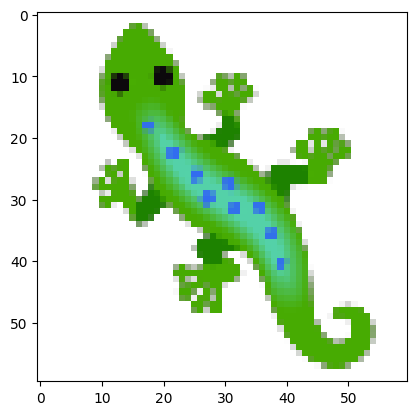

In [125]:
#@title Display Image { vertical-output: true}
for i,image in enumerate(images_to_display):
    plt.figure(3+i)
    plt.imshow(image)
pools = []
for gene in genes:
    pools.append(utils.make_gene_pool(gene, pool_size= 1000, height=HEIGHT, width=WIDTH, channels=CHANNELS, gene_size=8))
seeds = []
for pool in pools:
    seeds.append(pool[0].clone())

In [126]:
#@title Get Batch Image Partition { vertical-output: true}
partitions = len(paths)
if partitions == 1:
    part = [BATCH_SIZE]
div = BATCH_SIZE//partitions
rem = BATCH_SIZE % partitions
part = [div + 1 if i < rem else div for i in range(partitions)]
print(f"Batch image paritions = {part}. Batch Size of {BATCH_SIZE}. Number of Partitions = {partitions}")

Batch image paritions = [10]. Batch Size of 10. Number of Partitions = 1


In [127]:
#@title Generate Extra Genes for Multi Morphology GeneProp CA { vertical-output: true}
gene_2 = []
for idx,p in enumerate(part):
    gene = torch.zeros((1,HEIGHT,WIDTH), device=DEVICE)
    gene[:,HEIGHT//2,WIDTH//2] = idx
    gene_2.append(gene.tile(p, 1, 1, 1))
genes = torch.cat(gene_2, dim = 0)

In [128]:
#@title Create Path for Saving Models { vertical-output: true}
folder = "GeneProp"
path = f"{PATH}/" + folder
if not os.path.exists(path):
    os.makedirs(path)
    print(f"Path: {path} created")
else:
    print(f"Path: {path} already exists, all OK!")

Path: TRAINED_2/GeneProp already exists, all OK!


In [129]:
#@title Initialise GeneCA (static) and GeneProp CA for Trainign { vertical-output: true}
bases = [images[i].tile(part[i],1,1,1) for i in range(len(part))]
base = torch.cat(bases, dim =0 )
loss_log = []
with torch.no_grad():
    ncaPre = GeneCA(CHANNELS,hidden_n=64, gene_size=GENE_COUNT)
    ncaPre.load_state_dict(torch.load(f"{PATH}/Gene/GeneCA_gene_size_8.pth"))
    ncaPre.to(DEVICE).eval()
nca = GenePropCA(CHANNELS,HIDDEN_SIZE_PROP, gene_size=GENE_COUNT)
nca = nca.to(DEVICE)
optim = torch.optim.AdamW(nca.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=5000, gamma=0.3)
name = folder + "/" +type(nca).__name__ + "_gene_size_" +str(GENE_COUNT)

GeneProp/GenePropCA_gene_size_8


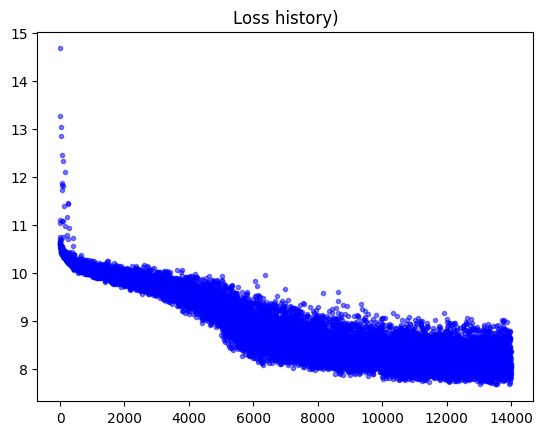

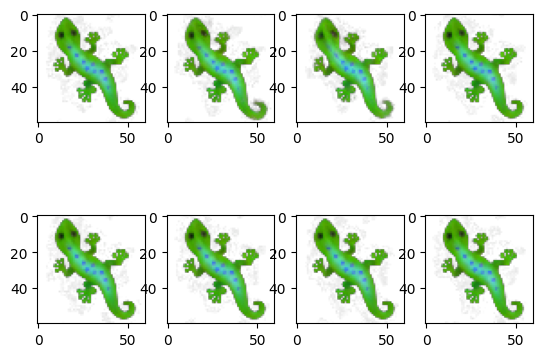

In [78]:
#@title Train GeneProp CA { vertical-output: true}
#TODO: Make it so that multi image gene props use the secondary genes
for i in range(TRAINING_ITERS + 1):
    loss = 0
    with torch.no_grad():
        idxs, x = utils.get_gene_pool(pools, part, seeds)

    itters = random.randrange(32,92)
    for _ in range( itters):
        x = ncaPre(x)
        x = nca(x)

    loss = (base - x[:, :4, :, :]).pow(2).sum() + 0.1 *(perchannel_conv(base, filters) - perchannel_conv(x[:, :4, :, :], filters) ).pow(2).sum()
    with torch.no_grad():
        loss.backward()
        for p in nca.parameters():
            p.grad /= (p.grad.norm() + 1e-8)
        optim.step()
        x = x.detach()
        optim.zero_grad()

    loss_log.append(loss.log().item())
    with torch.no_grad():
        pools = utils.udate_gene_pool(pools, x.clone().detach(), idxs, part)
    scheduler.step()

    if i % 100 == 0:
        print(f"Training itter {i}, loss = {loss.item()}")
        plt.clf()
        clear_output()
        plt.figure(1,figsize=(10, 4))
        plt.title('Loss history)')
        print(name)
        plt.plot(loss_log, '.', alpha=0.5, color = "b")
        utils.show_batch(x[2:10])
        plt.show(block=False)
        plt.pause(0.01)
    if i % 100 == 0:
        torch.save(nca.state_dict(), f"{PATH}/" + name + ".pth")

In [83]:
#@title Create Video { vertical-output: true}
del nca
del ncaPre
del optim
torch.cuda.empty_cache()
path_video = "Saved_frames/GenePropCA"
if not os.path.exists(path_video):
    os.makedirs(path_video)
    print(f"Path: {path_video} created")
else:
    print(f"Path: {path_video} already exists, all OK!")
'''seeds = [torch.tensor([0.0,1.0,0.0], device=DEVICE)]
seed_locs = [[30,30]]
seed_index = 0'''

seed_genes = [[0], [6], [5], [4], [3], [2], [1]]
seed_locs  = [[20, 20], [20, 80], [20, 140], [80, 20], [80, 80], [80, 140], [140, 80]]
seed_index = 0


nca = GeneCA(CHANNELS,hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT)
nca.load_state_dict(torch.load(f"{PATH}/Gene/GeneCA_gene_size_8.pth"))
nca.to(DEVICE).eval()
nca_prop = GenePropCA(CHANNELS,hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT)
nca_prop.load_state_dict(torch.load(f"{PATH}/GeneProp/GenePropCA_gene_size_8.pth"))
nca_prop.to(DEVICE).eval()
x_prime = torch.zeros((1,CHANNELS, HEIGHT, WIDTH), dtype=torch.float32).cuda()
place_seed(x_prime, 30, 30, [1])
frame_count = 500
for i in range(frame_count):
    x_prime = nca(x_prime)
    x_prime = x_prime.detach()
    if i > 50:
        x_prime = nca_prop(x_prime)
    write_frame(x_prime, path_video, i, HEIGHT, WIDTH,CHANNELS)
make_video(path_video, frame_count, HEIGHT, WIDTH)

Path: Saved_frames/GenePropCA already exists, all OK!


In [84]:
#@title Display Vide { vertical-output: true}
Video(path_video+'/output_video.mp4', embed=True, width=320, height=320)

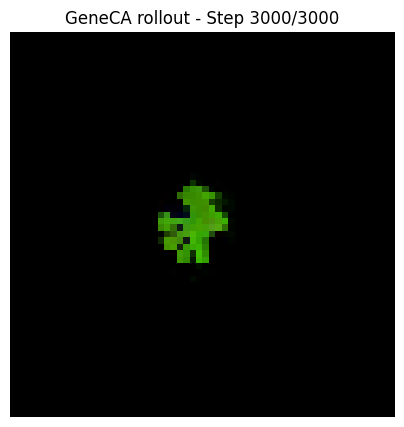

In [85]:
#@title Inspect GeneCA one sample { vertical-output: true}
from pathlib import Path
from IPython.display import display

INSPECT_STEPS = 3000 #@param {type:"integer"}
INSPECT_SEED = [1] #@param {type:"raw"}
if not torch.cuda.is_available():
    raise RuntimeError("Inspection requires CUDA because the NCA kernels use CUDA tensors.")
INSPECT_DEVICE = torch.device(DEVICE)

def _load_checkpoint(model, checkpoint):
    checkpoint_path = Path(checkpoint)
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    model.load_state_dict(torch.load(checkpoint_path, map_location=INSPECT_DEVICE))
    return model.to(INSPECT_DEVICE).eval()

def _make_inspection_seed(gene, height, width):
    return utils.make_gene_pool(gene, pool_size=1, height=height, width=width,
                                channels=CHANNELS, device=str(INSPECT_DEVICE),
                                gene_size=GENE_COUNT)

def _state_to_image(state):
    return state[0, :3].detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

def _show_snapshots(snapshots, title):
    columns = min(4, len(snapshots))
    rows = (len(snapshots) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, squeeze=False, figsize=(3 * columns, 3 * rows))
    for ax, (step, image) in zip(axes.flat, snapshots):
        ax.imshow(image)
        ax.set_title(f"Step {step}")
        ax.axis("off")
    for ax in axes.flat[len(snapshots):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def _rollout(step_fn, steps, snapshot_every, title, video_path):
    snapshots, frames = [], []
    with torch.no_grad():
        for step in range(steps + 1):
            image = _state_to_image(x_inspect)
            frames.append((image * 255).astype(np.uint8))
            if step == 0 or step % snapshot_every == 0 or step == steps:
                snapshots.append((step, image))
            if step < steps:
                x_inspect.copy_(step_fn(x_inspect))
    _show_snapshots(snapshots, title)
    video_path = Path(video_path)
    video_path.parent.mkdir(parents=True, exist_ok=True)
    height, width = frames[0].shape[:2]
    writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), 10.0, (width, height))
    if not writer.isOpened():
        raise RuntimeError(f"Could not open video writer: {video_path}")
    for frame in frames:
        writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))
    writer.release()
    display(Video(str(video_path), embed=True, width=320, height=320))
    return snapshots, video_path

def _watch_rollout(step_fn, steps, title):
    fig, ax = plt.subplots(figsize=(5, 5))
    image_artist = None
    display_handle = display(fig, display_id=True)
    with torch.no_grad():
        for step in range(steps):
            image = _state_to_image(x_inspect)
            if image_artist is None:
                image_artist = ax.imshow(image)
                ax.axis("off")
            else:
                image_artist.set_data(image)
            ax.set_title(f"{title} - Step {step + 1}/{steps}")
            display_handle.update(fig)
            x_inspect.copy_(step_fn(x_inspect))
    plt.close(fig)

gene_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                              f"{PATH}/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(INSPECT_SEED, HEIGHT, WIDTH)
_watch_rollout(lambda state: gene_model(state), INSPECT_STEPS, "GeneCA rollout")

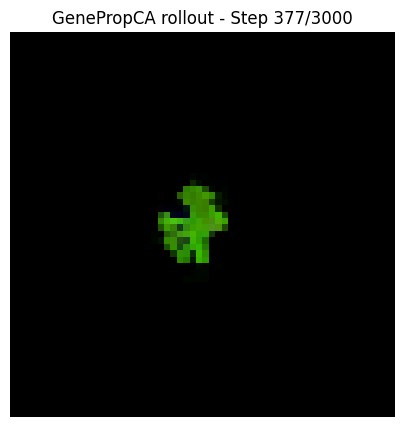

In [ ]:
#@title Inspect GeneProgatioCA one sample { vertical-output: true}
PROP_INSPECT_STEPS = 3000 #@param {type:"integer"}
PROP_WARMUP_STEPS = 50 #@param {type:"integer"}
PROP_INSPECT_SEED = [1] #@param {type:"raw"}
prop_base_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                                   f"{PATH}/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
prop_model = _load_checkpoint(GenePropCA(CHANNELS, hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT),
                              f"{PATH}/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(PROP_INSPECT_SEED, HEIGHT, WIDTH)
with torch.no_grad():
    for _ in range(PROP_WARMUP_STEPS):
        x_inspect.copy_(prop_base_model(x_inspect))
_watch_rollout(lambda state: prop_model(state), PROP_INSPECT_STEPS, "GenePropCA rollout")

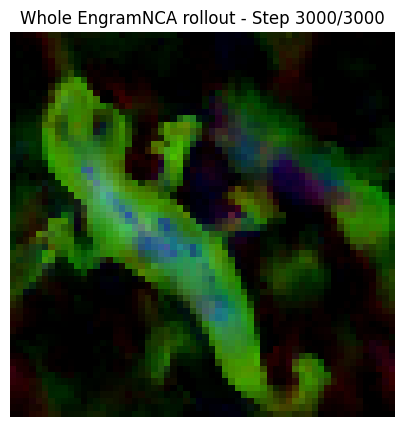

In [ ]:
#@title Inspect whole EngramNCA one sample { vertical-output: true}
ENGRAM_INSPECT_STEPS = 3000 #@param {type:"integer"}
ENGRAM_INSPECT_SEED = [1] #@param {type:"raw"}
engram_gene_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                              f"{PATH}/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
engram_prop_model = _load_checkpoint(GenePropCA(CHANNELS, hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT),
                                     f"{PATH}/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(ENGRAM_INSPECT_SEED, HEIGHT, WIDTH)
engram_switch_step = 50
def _engram_step(state):
    state = engram_gene_model(state)
    if _engram_step.step >= engram_switch_step:
        state = engram_prop_model(state)
    _engram_step.step += 1
    return state
_engram_step.step = 0
_watch_rollout(_engram_step, ENGRAM_INSPECT_STEPS, "Whole EngramNCA rollout")

engram step: 5000/5000  intervention: continuous


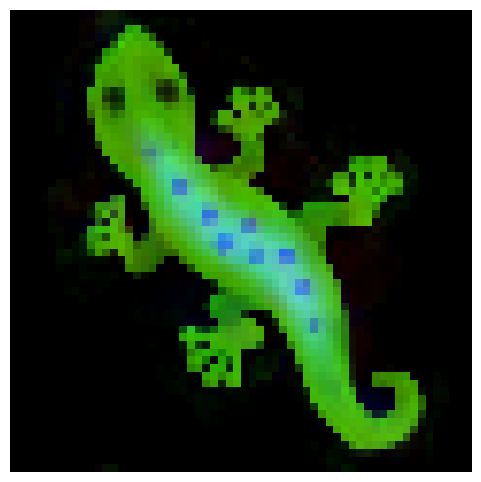

Completed engram rollout with continuous intervention.


In [136]:
#@title Hidden-channel intervention rollout { vertical-output: true}
from time import sleep

from IPython.display import clear_output
import matplotlib.pyplot as plt

MODEL_TYPE = "engram" #@param ["geneca", "genepropca", "engram"] <-- "engram" = GeneCA + GenePropCA (whole gecko)
ENGRAM_SEED = [1] # gene GenePropCA was trained with (cell 18: genes = [[1]])
ENGRAM_SWITCH_STEP = 50 # GenePropCA starts running at this step, same as the whole-EngramNCA inspect cell
GROW_HEIGHT, GROW_WIDTH = (60, 60) if MODEL_TYPE != "geneca" else (HEIGHT, WIDTH) # GenePropCA was trained on 60x60
SHAPE_INDEX = 0 #@param {type:"integer"} 0=square, 1=circle, 2=triangle
SHAPE_GENES = [[0], [6], [5], [4], [3], [2], [1]]  # torso, head, tail, leg1, leg2, leg3, leg4 (ignored in "engram" mode)
N_STEPS = 5000
MATURE_STEP = 300 if MODEL_TYPE == "engram" else 70 # intervention starts here; the gecko needs longer to mature

# "none" = no intervention; "freeze" = clamp after every update;
# "periodic" = reset every RESET_PERIOD steps; "continuous" = partial reset after every update.
INTERVENTION = "continuous"
FREEZE_CHANNELS = None # None = all hidden, or e.g. [10] / [5, 10] (partial)
RESET_PERIOD = 150
RESTORE_B = 0.1
RESTORE_CHANNELS = None # None = all hidden channels, or e.g. [10]

MODEL_CONFIG = {
    "geneca": (GeneCA, HIDDEN_SIZE, f"{PATH}/Gene/GeneCA_gene_size_{GENE_COUNT}.pth"),
    "genepropca": (GenePropCA, HIDDEN_SIZE_PROP, f"{PATH}/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth"),
}
def _load_model(model_type):
    model_class, model_hidden_size, model_checkpoint = MODEL_CONFIG[model_type]
    return _load_checkpoint(model_class(CHANNELS, hidden_n=model_hidden_size, gene_size=GENE_COUNT), model_checkpoint)

if MODEL_TYPE == "engram":
    engram_gene_ca = _load_model("geneca")
    engram_prop_ca = _load_model("genepropca")
    def grow_step(state, step):
        state = engram_gene_ca(state)          # draws body parts from the local genes
        if step >= ENGRAM_SWITCH_STEP:
            state = engram_prop_ca(state)      # rewrites the genes so the parts land in the right places
        return state
    seed_gene = ENGRAM_SEED
elif MODEL_TYPE in MODEL_CONFIG:
    grow_ca = _load_model(MODEL_TYPE)
    def grow_step(state, step):
        return grow_ca(state)
    if not 0 <= SHAPE_INDEX < len(SHAPE_GENES):
        raise ValueError(f"SHAPE_INDEX must be between 0 and {len(SHAPE_GENES) - 1}")
    seed_gene = SHAPE_GENES[SHAPE_INDEX]
else:
    raise ValueError(f"unknown MODEL_TYPE: {MODEL_TYPE!r}; choose 'geneca', 'genepropca' or 'engram'")
x_grow = _make_inspection_seed(seed_gene, GROW_HEIGHT, GROW_WIDTH)
hidden_channels = list(range(3, CHANNELS))

def _channel_indices(channels):
    selected = hidden_channels if channels is None else channels
    if any(channel < 3 or channel >= CHANNELS for channel in selected):
        raise ValueError(f"hidden channel indices must be between 3 and {CHANNELS - 1}")
    return torch.as_tensor(selected, device=x_grow.device, dtype=torch.long)

def _make_restore(target, strength, channels):
    indices = _channel_indices(channels)
    channel_mask = torch.zeros_like(target, dtype=torch.bool)
    channel_mask[:, indices] = True
    return channel_mask, target.clone(), strength

def _apply_restore(state, restore):
    channel_mask, target, strength = restore
    restored = (1.0 - strength) * state + strength * target
    return torch.where(channel_mask, restored, state)

if INTERVENTION not in {"none", "freeze", "periodic", "continuous"}:
    raise ValueError(f"unknown INTERVENTION: {INTERVENTION}")
if RESET_PERIOD <= 0:
    raise ValueError("RESET_PERIOD must be positive")
if not 0.0 <= RESTORE_B <= 1.0:
    raise ValueError("RESTORE_B must be between 0 and 1")
restore = None
reset = None

with torch.inference_mode():
    for step in range(N_STEPS):
        if step == MATURE_STEP:
            if INTERVENTION == "freeze":
                restore = _make_restore(x_grow, 1.0, FREEZE_CHANNELS)
            elif INTERVENTION == "continuous":
                restore = _make_restore(x_grow, RESTORE_B, RESTORE_CHANNELS)
            elif INTERVENTION == "periodic":
                reset = _make_restore(x_grow, 1.0, None)
            elif INTERVENTION != "none":
                raise ValueError(f"unknown INTERVENTION: {INTERVENTION}")
        if reset is not None and step > MATURE_STEP and (step - MATURE_STEP) % RESET_PERIOD == 0:
            x_grow = _apply_restore(x_grow, reset)
        x_grow = grow_step(x_grow, step)
        if restore is not None:
            x_grow = _apply_restore(x_grow, restore)
        if step % max(1, N_STEPS // 100) == 0 or step == N_STEPS - 1:
            clear_output(wait=True)
            print(
                f"{MODEL_TYPE} step: {step + 1}/{N_STEPS}  "
                f"intervention: {INTERVENTION}"
            )
            plt.figure(figsize=(6, 6))
            plt.imshow(_state_to_image(x_grow), interpolation="nearest")
            plt.axis("off")
            plt.show()
            plt.close()
            sleep(0.5)

print(f"Completed {MODEL_TYPE} rollout with {INTERVENTION} intervention.")


In [ ]:
#@title Inspect whole EngramNCA one sample with damage { vertical-output: true}
# Self-contained: only needs the Imports + Setup cells (CHANNELS, GENE_COUNT, HIDDEN_SIZE, PATH, DEVICE).
from pathlib import Path
from IPython.display import display

DMG_CHECKPOINT_DIR = PATH          #@param {type:"raw"} <-- folder holding Gene/ and GeneProp/ checkpoints
DMG_HIDDEN_SIZE_PROP = 124         #@param {type:"integer"} <-- must match the trained GenePropCA
DMG_HEIGHT = 60                    #@param {type:"integer"} <-- grid size (GenePropCA was trained on 60x60)
DMG_WIDTH = 60                     #@param {type:"integer"}
DMG_SEED = [1]                     #@param {type:"raw"} <-- gene indices for the seed, same format as `genes`
DMG_STEPS = 1000                   #@param {type:"integer"}
DMG_SWITCH_STEP = 50               #@param {type:"integer"} <-- step at which GenePropCA starts running
DMG_DISPLAY_EVERY = 5              #@param {type:"integer"} <-- redraw live view every N steps

# Damage schedule: the damage is applied right BEFORE the model update at each listed step.
DAMAGE_STEPS = [300, 600]          #@param {type:"raw"}
# "circle"  : wipe a disc of radius DAMAGE_RADIUS at DAMAGE_CENTER (row, col)
# "half"    : wipe one half of the grid, chosen by DAMAGE_SIDE ("left", "right", "top", "bottom")
# "pixels"  : wipe a random DAMAGE_FRACTION of all cells
# "noise"   : add Gaussian noise (std DAMAGE_NOISE_STD) inside the DAMAGE_CENTER/DAMAGE_RADIUS disc
DAMAGE_TYPE = "circle"             #@param ["circle", "half", "pixels", "noise"]
DAMAGE_CENTER = None               #@param {type:"raw"} <-- (row, col); None = random point on the grown body
DAMAGE_RADIUS = 10                 #@param {type:"integer"}
DAMAGE_SIDE = "left"               #@param ["left", "right", "top", "bottom"]
DAMAGE_FRACTION = 0.3              #@param {type:"number"}
DAMAGE_NOISE_STD = 0.5             #@param {type:"number"}
# Which channels the damage touches:
# "all"      : RGB, alpha, hidden AND gene channels (cells lose their identity, GenePropCA must re-spread it)
# "no_genes" : everything except gene channels (cells keep their identity)
# "genes"    : gene channels only (body intact, identity scrambled)
DAMAGE_CHANNELS = "all"            #@param ["all", "no_genes", "genes"]

if not torch.cuda.is_available():
    raise RuntimeError("EngramNCA kernels use CUDA tensors; a GPU is required.")
_dmg_device = torch.device(DEVICE)

def _dmg_load(model, checkpoint):
    checkpoint = Path(checkpoint)
    if not checkpoint.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")
    model.load_state_dict(torch.load(checkpoint, map_location=_dmg_device))
    return model.to(_dmg_device).eval()

def _dmg_image(state):
    return state[0, :3].detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

def _dmg_channel_slice():
    if DAMAGE_CHANNELS == "all":
        return slice(0, CHANNELS)
    if DAMAGE_CHANNELS == "no_genes":
        return slice(0, CHANNELS - GENE_COUNT)
    if DAMAGE_CHANNELS == "genes":
        return slice(CHANNELS - GENE_COUNT, CHANNELS)
    raise ValueError(f"unknown DAMAGE_CHANNELS: {DAMAGE_CHANNELS!r}")

def _dmg_center(state):
    if DAMAGE_CENTER is not None:
        return DAMAGE_CENTER
    alive = (state[0, 3] > 0.1).nonzero()
    if len(alive) == 0:
        return (DMG_HEIGHT // 2, DMG_WIDTH // 2)
    row, col = alive[torch.randint(len(alive), (1,))].squeeze(0).tolist()
    return (row, col)

def _dmg_mask(state):
    """Boolean (H, W) mask of the cells to damage."""
    rows = torch.arange(DMG_HEIGHT, device=state.device)[:, None]
    cols = torch.arange(DMG_WIDTH, device=state.device)[None, :]
    if DAMAGE_TYPE in ("circle", "noise"):
        cr, cc = _dmg_center(state)
        return (rows - cr) ** 2 + (cols - cc) ** 2 <= DAMAGE_RADIUS ** 2
    if DAMAGE_TYPE == "half":
        masks = {"left": cols < DMG_WIDTH // 2, "right": cols >= DMG_WIDTH // 2,
                 "top": rows < DMG_HEIGHT // 2, "bottom": rows >= DMG_HEIGHT // 2}
        return masks[DAMAGE_SIDE].expand(DMG_HEIGHT, DMG_WIDTH)
    if DAMAGE_TYPE == "pixels":
        return torch.rand(DMG_HEIGHT, DMG_WIDTH, device=state.device) < DAMAGE_FRACTION
    raise ValueError(f"unknown DAMAGE_TYPE: {DAMAGE_TYPE!r}")

def _apply_damage(state):
    mask = _dmg_mask(state)
    channels = _dmg_channel_slice()
    if DAMAGE_TYPE == "noise":
        state[:, channels] += torch.randn_like(state[:, channels]) * DAMAGE_NOISE_STD * mask
    else:
        state[:, channels] *= ~mask
    return state

dmg_gene_model = _dmg_load(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                           f"{DMG_CHECKPOINT_DIR}/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
dmg_prop_model = _dmg_load(GenePropCA(CHANNELS, hidden_n=DMG_HIDDEN_SIZE_PROP, gene_size=GENE_COUNT),
                           f"{DMG_CHECKPOINT_DIR}/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth")

x_dmg = utils.make_gene_pool(DMG_SEED, pool_size=1, height=DMG_HEIGHT, width=DMG_WIDTH,
                             channels=CHANNELS, device=str(_dmg_device), gene_size=GENE_COUNT)
damage_steps = set(DAMAGE_STEPS)
snapshots = []   # (label, image) pairs: before/after each damage + final

fig, ax = plt.subplots(figsize=(5, 5))
ax.axis("off")
artist = ax.imshow(_dmg_image(x_dmg), interpolation="nearest")
handle = display(fig, display_id=True)
with torch.no_grad():
    for step in range(DMG_STEPS):
        if step in damage_steps:
            snapshots.append((f"Step {step}: before", _dmg_image(x_dmg)))
            x_dmg = _apply_damage(x_dmg)
            snapshots.append((f"Step {step}: after {DAMAGE_TYPE}", _dmg_image(x_dmg)))
        x_dmg = dmg_gene_model(x_dmg)
        if step >= DMG_SWITCH_STEP:
            x_dmg = dmg_prop_model(x_dmg)
        if step % DMG_DISPLAY_EVERY == 0 or step == DMG_STEPS - 1:
            artist.set_data(_dmg_image(x_dmg))
            hit = [s for s in DAMAGE_STEPS if s <= step]
            ax.set_title(f"Step {step + 1}/{DMG_STEPS}" + (f"  (damaged at {hit})" if hit else ""))
            handle.update(fig)
plt.close(fig)
snapshots.append((f"Final step {DMG_STEPS}", _dmg_image(x_dmg)))

# Before/after summary grid
cols = min(4, len(snapshots))
rows = (len(snapshots) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, squeeze=False, figsize=(3 * cols, 3 * rows))
for a, (label, img) in zip(axes.flat, snapshots):
    a.imshow(img, interpolation="nearest")
    a.set_title(label, fontsize=9)
    a.axis("off")
for a in axes.flat[len(snapshots):]:
    a.axis("off")
fig.suptitle(f"EngramNCA damage: {DAMAGE_TYPE}, channels={DAMAGE_CHANNELS}, seed={DMG_SEED}")
plt.tight_layout()
plt.show()